> **Trainierte Modelle:** Dieses Notebook lädt das fertige Modell aus `models/` und trainiert nicht neu. Zum Neutrainieren in den Parametern `TRAIN_MODEL = True` setzen.

Der ursprüngliche v4-Lauf: 32 Zahlen wie v3, VGG-Gewicht 1e-5, 25 Epochen. Ergebnis: starkes Raster (5,95 statt 0,056 im Original), aber der beste Klassen-Treffer aller Versionen (41,9 %).

## 💭 Starting point: the question this version answers

**Thorsten's observation:** after running v3, the reconstructions are still clearly blurry, even though the embedding itself got measurably more useful (k-NN probe: 0.338 vs. 0.269 for a raw-pixel baseline). The question: what has the biggest impact on reducing that blur?

**Analysis and proposed directions (discussed before building this notebook):**
1. **Root cause**: pixel-wise reconstruction loss (`mse`/`binary_crossentropy`) structurally rewards the decoder for hedging toward a smooth average whenever it's uncertain about fine texture, because that minimizes *expected* per-pixel error. This is the same mechanism that makes plain VAEs look soft while GANs look sharp — it's the fundamental cause of blur, not a tuning problem.
2. Three levers were ranked by impact: (a) a bigger latent bottleneck (quick, cheap, moderate payoff — v3 already explored some of this ceiling with its 32-dim embedding), (b) a better-matched reconstruction loss — perceptual and/or adversarial (the biggest ceiling on sharpness specifically, since it directly targets the mechanism that causes blur), (c) fixing `Conv2DTranspose` checkerboard/blur artifacts (contained, modest payoff).
3. **Decision**: pursue (b), and within that, **perceptual loss only** — no discriminator/adversarial loss. This keeps training a plain `compile(loss=...)` + `fit()` call, no custom `train_step`, trading away whatever extra sharpness a GAN-style discriminator could add in exchange for predictable, stable training. (No course reference material exists for GAN/perceptual-loss patterns, so this is built from general ML knowledge rather than an existing template, unlike v2's VAE conversion, which had `vae.ipynb` to adapt from.)

---

## 📝 Changelog: v4 (perceptual loss) vs. v3 (latent quality) baseline

**Motivation:** v3 fixed the diagnosable issues around the *latent space* (bottleneck size, capacity, loss type, training schedule, visualization), but left reconstructions blurry — because none of those changes touch the actual mechanism that causes blur. This version isolates the reconstruction loss as the **only** independent variable: architecture, `EMBEDDING_DIM`, and the training schedule/callbacks are all unchanged from v3.

**Why pixel loss causes blur (the mechanism):**
When a decoder is trained to minimize per-pixel MSE/BCE and is uncertain about the exact position or value of a fine edge or texture, its optimal strategy is to output the *average* of the plausible options — a smooth blend minimizes expected squared error better than committing to any single sharp (but possibly slightly wrong) version. A perceptual loss instead compares images in a *feature space* learned by a network trained on natural images (here, a frozen, pretrained VGG16) — matching feature activations penalizes "looks structurally wrong" rather than "not pixel-identical," which rewards plausible sharp detail instead of a safe blur.

**Changes made:**
1. **New frozen VGG16 feature extractor**, using layers `block1_conv2` (32×32), `block2_conv2` (16×16), `block3_conv3` (8×8). Deeper layers (`block4_*` → 4×4, `block5_*` → 1–2×2) were deliberately excluded — on a 32×32 CIFAR-10 input they collapse to a resolution too coarse to carry anything beyond rough average colour/brightness, while still roughly doubling the compute cost. See section 2a.
2. **New composite loss** (`perceptual_loss`): `pixel_mse + PERCEPTUAL_WEIGHT * feature_mse`, replacing the plain `loss="mse"` from v3. `PERCEPTUAL_WEIGHT` was calibrated from a diagnostic cell that measures both terms' raw magnitudes on a single batch *before* training starts — pixel-MSE and raw VGG-feature-MSE differ by several orders of magnitude, so a naive weight of `1.0` would let the perceptual term completely dominate the gradient and make the pixel term noise. See the diagnostic cell's printed ratio and the value actually used, in section 2a.
3. **`@keras.saving.register_keras_serializable`** on `perceptual_loss`, so `autoencoder.save(...)` doesn't leave behind an unresolvable custom loss on reload — same spirit as v2's `get_config`/`from_config` fix for its VAE class. Scope/limitation: this only makes the function resolvable *by name* in a session where `feature_extractor` is already defined; it does not serialize the VGG sub-model or the closure into the `.keras` file itself. Not an issue here, since this notebook never reloads the composite `autoencoder` model, only saves it.
4. Artifacts saved under `_v4` suffixes (`models/encoder_v4.keras`, etc., `./checkpoint_v4.keras`, `./logs_v4`).
5. **New section 4a**: a variance-of-Laplacian sharpness metric, computed on the ground-truth images, v3's reconstructions (loaded from the already-saved `models/autoencoder_v3.keras`), and this notebook's own reconstructions — a number for "is it actually sharper," not just an eyeballed comparison of two image grids.
6. **Unchanged from v3**, deliberately, to isolate the loss function as the only variable: the encoder/decoder architecture (same 4-stage conv/deconv stack), `EMBEDDING_DIM = 32`, `EPOCHS = 25`, all callbacks (`EarlyStopping`, `ReduceLROnPlateau`, `ModelCheckpoint`), and the PCA/t-SNE/k-NN class-separability analysis from section 5.

**Caveats — read before expecting miracles:**
- `val_loss`'s absolute scale is **not** comparable to v3's `~0.0113` — it's now a different composite quantity (pixel MSE + weighted VGG-feature MSE), not pure pixel MSE. Compare sharpness via section 4a and visual inspection, not by comparing loss numbers across notebooks.
- `PERCEPTUAL_WEIGHT` was hand-calibrated from one diagnostic batch, not swept across a range — treat it as a reasonable starting point, not a principled optimum.
- Expect training to run noticeably slower than v3's ~88s/epoch, since each step now also runs two frozen VGG16 forward passes (one for the real image, one for the reconstruction) — the actual measured time is reported after training below.
- This version does **not** address latent bottleneck size or `Conv2DTranspose` checkerboard artifacts — those were the other two levers, explicitly deferred by choice, not solved here.
- A perceptual loss alone (without an adversarial term) typically narrows the blur gap but rarely eliminates it completely — reconstructions may still show visible, if qualitatively different, softness. That's the honest ceiling of this specific lever.

# Autoencoders on CIFAR-10

## Task Description

We have seen how to build an Autoencoder for the grayscale images of the Fashion-MNIST dataset. In this Exercise, you will build one for the CIFAR-10 dataset (https://www.cs.toronto.edu/~kriz/cifar.html). This dataset contains **color** images with a 32x32 resolution.

### Preparation


In [1]:
import matplotlib.pyplot as plt


def sample_batch(dataset):
    batch = dataset.take(1).get_single_element()
    if isinstance(batch, tuple):
        batch = batch[0]
    return batch.numpy()


def display(
    images, n=10, size=(20, 3), cmap="gray_r", as_type="float32", save_to=None
):
    """
    Displays n images from each one of the supplied arrays.
    """
    if images.max() > 1.0:
        images = images / 255.0
    elif images.min() < 0.0:
        images = (images + 1.0) / 2.0

    plt.figure(figsize=size)
    for i in range(n):
        _ = plt.subplot(1, n, i + 1)
        plt.imshow(images[i].astype(as_type), cmap=cmap)
        plt.axis("off")

    if save_to:
        plt.savefig(save_to)
        print(f"\nSaved to {save_to}")

    plt.show()


In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import keras
from tensorflow.keras import layers, models, datasets, callbacks
from tensorflow.keras.applications import vgg16
import tensorflow.keras.backend as K

# v3 addition: needed for the PCA / t-SNE visualizations and the k-NN probe
# in sections 5a/5b below.
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# v4 addition: needed for the variance-of-Laplacian sharpness metric in
# section 4a below.
from scipy.ndimage import convolve


I0000 00:00:1793543095.777640 2018157 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793543096.924473 2018157 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 0. Parameters <a name="parameters"></a>

In [3]:
IMAGE_SIZE = 32
CHANNELS = 3
BATCH_SIZE = 100
BUFFER_SIZE = 1000
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 32  # unchanged from v3
EPOCHS = 25  # unchanged from v3

# v4 addition: perceptual-loss settings -- see changelog points 1-2 and
# section 2a below.
VGG_LAYER_NAMES = ["block1_conv2", "block2_conv2", "block3_conv3"]
PERCEPTUAL_WEIGHT = 1e-5  # [Gewicht: festgelegt] placeholder -- calibrated against the diagnostic cell in section 2a

# Eigene Modelle laden statt neu trainieren. True trainiert neu.
TRAIN_MODEL = False

## 1. Prepare the data <a name="prepare"></a>

In [4]:
# Load the data
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

In [5]:
# Preprocess the data

def preprocess(imgs):
    """
    Normalize and reshape the images
    """
    imgs = imgs.astype("float32") / 255.0
    imgs = imgs.reshape(len(imgs),imgs.shape[1],imgs.shape[2],3)
    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

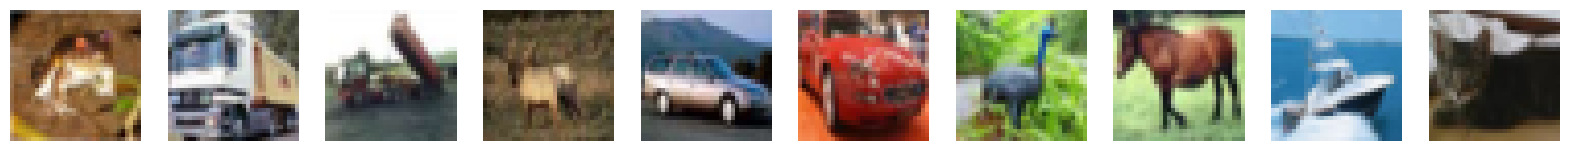

In [6]:
# Show some items of clothing from the training set
display(x_train)

## 2. Build the autoencoder <a name="build"></a>

In [7]:
# Encoder
# (unchanged from v3: 4 Conv2D stages, 32->64->128->256 filters, with
# BatchNormalization + Activation("relu") after each.)
encoder_input = layers.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input"
)

x = layers.Conv2D(32, (3, 3), strides=2, padding="same")(encoder_input)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(64, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(128, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2D(256, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

shape_before_flattening = K.int_shape(x)[1:]  # the decoder will need this!

x = layers.Flatten()(x)
encoder_output = layers.Dense(EMBEDDING_DIM, name="encoder_output")(x)

encoder = models.Model(encoder_input, encoder_output, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 2, 2, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2, 2, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 32)             │        32,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,136 (1.61 MB)

 Trainable params: 422,176 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [8]:
# Decoder
# (unchanged from v3: mirrors the encoder's 4 stages, same BatchNormalization.)
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(int(np.prod(shape_before_flattening)))(decoder_input)
x = layers.Reshape(shape_before_flattening)(x)

x = layers.Conv2DTranspose(256, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2DTranspose(128, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2DTranspose(64, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

x = layers.Conv2DTranspose(32, (3, 3), strides=2, padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)

decoder_output = layers.Conv2D(
    CHANNELS,
    (3, 3),
    strides=1,
    activation="sigmoid",
    padding="same",
    name="decoder_output",
)(x)

decoder = models.Model(decoder_input, decoder_output, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │        33,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 4, 4, 256)      │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 8, 8, 128)      │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 32, 32, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,013,955 (3.87 MB)

 Trainable params: 1,012,995 (3.86 MB)

 Non-trainable params: 960 (3.75 KB)

In [9]:
# Autoencoder
autoencoder = models.Model(
    encoder_input, decoder(encoder_output), name="autoencoder"
)  # decoder(encoder_output)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 2, 2, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2, 2, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 2, 2, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 32)             │        32,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 32, 32, 3)      │     1,013,955 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,437,091 (5.48 MB)

 Trainable params: 1,435,171 (5.47 MB)

 Non-trainable params: 1,920 (7.50 KB)

## 2a. Perceptual loss: a frozen VGG16 feature extractor <a name="perceptual"></a>

A perceptual loss compares images in the feature space of a network already trained on natural images, instead of raw pixel space. We use `VGG16` pretrained on ImageNet, frozen (never updated), and read off activations from a few of its early/mid convolutional layers.

CIFAR-10 images are only 32×32, and VGG16 halves the spatial size at every pooling stage. Tracking how a 32×32 input shrinks through the network:

| layer | spatial size |
|---|---|
| `block1_conv1` / `block1_conv2` | 32×32 |
| `block1_pool` | 16×16 |
| `block2_conv1` / `block2_conv2` | 16×16 |
| `block2_pool` | 8×8 |
| `block3_conv1` / `block3_conv2` / `block3_conv3` | 8×8 |
| `block3_pool` | 4×4 |
| `block4_*` | 4×4 |
| `block5_*` | 2×2, collapsing to 1×1 after the final pool |

We use `block1_conv2`, `block2_conv2`, and `block3_conv3` (32×32, 16×16, 8×8) — low/mid-level edge and texture features that are still meaningfully spatial for a 32×32 image. `block4_*`/`block5_*` are deliberately excluded: at 4×4 or 1–2×2 they mostly encode "average colour/brightness of the whole image," which pixel MSE already captures, while costing roughly double the compute for little extra signal.

In [10]:
vgg = vgg16.VGG16(
    weights="imagenet", include_top=False, input_shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
)
vgg.trainable = False

feature_extractor = models.Model(
    vgg.input,
    [vgg.get_layer(name).output for name in VGG_LAYER_NAMES],
    name="vgg16_feature_extractor",
)
feature_extractor.trainable = False

print(feature_extractor.output_shape)

[(None, 32, 32, 64), (None, 16, 16, 128), (None, 8, 8, 256)]


In [11]:
def to_vgg_input(images_01):
    """Converts images from this notebook's [0, 1] RGB range to what VGG16's
    ImageNet weights expect (0-255 scale, BGR order, ImageNet mean-subtracted)."""
    return vgg16.preprocess_input(images_01 * 255.0)

In [12]:
# v4: check the raw magnitudes of the pixel and feature loss terms on the
# freshly-initialized (untrained) autoencoder, *before* picking
# PERCEPTUAL_WEIGHT -- see changelog point 2. Naively weighting the two terms
# equally would let whichever one happens to be numerically larger dominate
# the gradient.
diagnostic_batch = x_train[:BATCH_SIZE]
diagnostic_recon = autoencoder(diagnostic_batch, training=False).numpy()

pixel_mse_sample = np.mean((diagnostic_batch - diagnostic_recon) ** 2)

true_feats_sample = feature_extractor(to_vgg_input(diagnostic_batch), training=False)
pred_feats_sample = feature_extractor(to_vgg_input(diagnostic_recon), training=False)
per_layer_mse = [
    float(np.mean((t.numpy() - p.numpy()) ** 2))
    for t, p in zip(true_feats_sample, pred_feats_sample)
]
feature_mse_sample = float(np.mean(per_layer_mse))

print(f"pixel MSE (unweighted):           {pixel_mse_sample:.6f}")
print(f"per-layer feature MSE:            {[round(v, 2) for v in per_layer_mse]}")
print(f"feature MSE (unweighted, avg):    {feature_mse_sample:.6f}")
print(f"ratio pixel_mse / feature_mse:    {pixel_mse_sample / feature_mse_sample:.8f}")
print(f"PERCEPTUAL_WEIGHT * feature_mse:  {PERCEPTUAL_WEIGHT * feature_mse_sample:.6f}")

pixel MSE (unweighted):           0.060592
per-layer feature MSE:            [53229.21, 366848.81, 588358.19]
feature MSE (unweighted, avg):    336145.403646
ratio pixel_mse / feature_mse:    0.00000018
PERCEPTUAL_WEIGHT * feature_mse:  3.361454


### Gewichtung der Note: wo festgelegt, wo verwendet

Im Code sind die Stellen mit `[Gewicht]` markiert.

| Gewicht | Wert | Festgelegt | So ermittelt | Verwendet |
|---|---|---|---|---|
| `PERCEPTUAL_WEIGHT` (VGG gegen MSE) | 0,00001 | Abschnitt 0, Parameter | Von Hand gesetzt, keine Testreihe. Der Code nennt ihn einen Platzhalter | Letzte Zeile von `perceptual_loss` direkt unter diesem Text, aktiv über `compile` in Abschnitt 3 |

**Die Diagnosezelle direkt über diesem Text zeigt die Wirkung:** Am untrainierten Modell ist die MSE 0,0606 und der gewichtete VGG-Teil 3,36, also rund 55-mal so groß. Der Wert gleicht die beiden Teile demnach nicht aus. Er blieb trotzdem für diesen Lauf.

**Anteile:** VGG stellt am Start 98,1 % der Summe (50-mal die MSE auf diesen Testbildern), am Ende 98,7 % (78-mal).

**Die drei VGG-Stellen** zählen laut Formel gleich. Weil ihre Rohwerte verschieden groß sind, stellt am Ende `block3_conv3` rund 54 %, `block2_conv2` rund 41 % und `block1_conv2` rund 5 % des VGG-Werts.

Anteile: erste 1.000 Testbilder, berechnet mit `v6_experiments/note_terms.py`, Werte in `v6_experiments/runs/note_terms.json`.

In [13]:
@keras.saving.register_keras_serializable(package="autoencoder_v4")
def perceptual_loss(y_true, y_pred):
    pixel_mse = K.mean(K.square(y_true - y_pred), axis=[1, 2, 3])

    true_feats = feature_extractor(to_vgg_input(y_true), training=False)
    pred_feats = feature_extractor(to_vgg_input(y_pred), training=False)
    feature_mse = sum(
        K.mean(K.square(t - p), axis=[1, 2, 3]) for t, p in zip(true_feats, pred_feats)
    ) / len(true_feats)

    # [Gewicht: verwendet]
    return pixel_mse + PERCEPTUAL_WEIGHT * feature_mse

## 3. Train the autoencoder <a name="train"></a>

In [14]:
# Compile the autoencoder
# v4: loss "mse" -> perceptual_loss (pixel MSE + weighted VGG-feature MSE) --
# see changelog point 2 and the diagnostic cell in section 2a.
autoencoder.compile(optimizer="adam", loss=perceptual_loss)

In [15]:
# Create a model save checkpoint
# (unchanged from v3: EarlyStopping/ReduceLROnPlateau/ModelCheckpoint(monitor="val_loss"),
# kept identical on purpose so the loss function is the only variable that
# differs from v3. Paths updated to _v4.)
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint_v4.keras",
    save_weights_only=False,
    save_freq="epoch",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs_v4")
early_stopping_callback = callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
)
reduce_lr_callback = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1
)

In [16]:
if TRAIN_MODEL:
    # v4: expect this to run noticeably slower per epoch than v3's ~88s/epoch,
    # since every step now also runs two extra frozen VGG16 forward passes
    # (one for the real image, one for the reconstruction) -- see changelog.
    autoencoder.fit(
        x_train,
        x_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        validation_data=(x_test, x_test),
        callbacks=[
            model_checkpoint_callback,
            tensorboard_callback,
            early_stopping_callback,
            reduce_lr_callback,
        ],
    )
else:
    autoencoder.set_weights(models.load_model("./models/autoencoder_v4.keras", compile=False).get_weights())

In [17]:
if TRAIN_MODEL:
    # Save the final models
    # v4: saved under _v4 suffixes -- see changelog point 4.
    from pathlib import Path
    Path("./models").mkdir(parents=True, exist_ok=True)
    autoencoder.save("./models/autoencoder_v4.keras")
    encoder.save("./models/encoder_v4.keras")
    decoder.save("./models/decoder_v4.keras")

## 4. Reconstruct using the autoencoder <a name="reconstruct"></a>

In [18]:
n_to_predict = 5000
example_images = x_test[:n_to_predict]
example_labels = y_test[:n_to_predict]

  1/157 ━━━━━━━━━━━━━━━━━━━━ 27s 174ms/step

  8/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step   

 15/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step

 21/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

 27/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

 33/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

... (22 outputs left out)

155/157 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step


Example real images


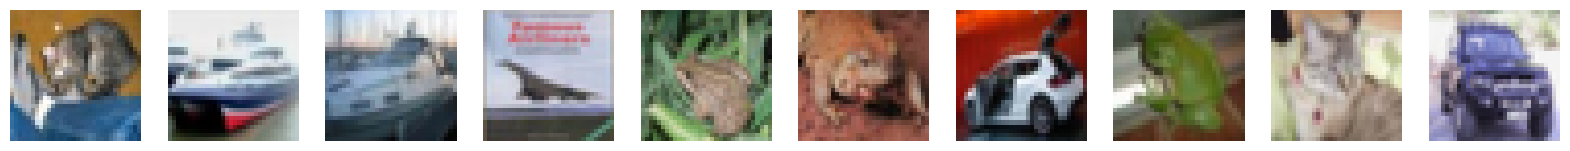

Reconstructions


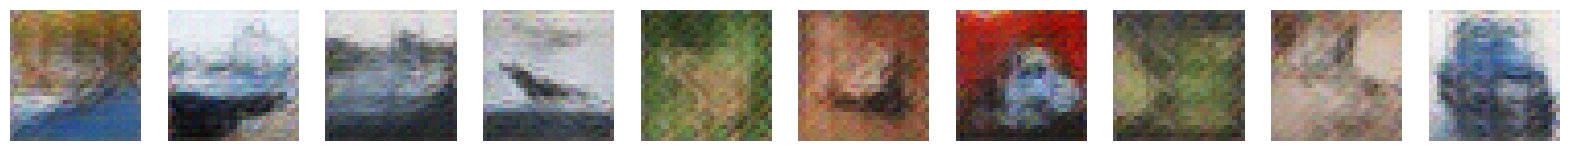

In [19]:
predictions = autoencoder.predict(example_images)

print("Example real images")
display(example_images)
print("Reconstructions")
display(predictions)

### 4a. Quantifying the blur: variance-of-Laplacian sharpness

A quick, dependency-light way to measure "how blurry" an image is: convolve its luma (grayscale) channel with a 3×3 Laplacian kernel (a basic edge detector) and look at the *variance* of the response. Sharp edges and fine texture produce large, varied Laplacian responses; a blurry image's edges are soft, so the response stays small and flat almost everywhere — lower variance. This is the same kind of metric classic "is this photo out of focus" detectors use.

We compare three groups on the same 5000 example images: the ground-truth images (the ceiling), v3's reconstructions (reloaded from `models/autoencoder_v3.keras`, saved by the already-executed v3 notebook), and this notebook's own (v4) reconstructions.

  1/157 ━━━━━━━━━━━━━━━━━━━━ 25s 162ms/step

  9/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step   

 16/157 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

 23/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step

 29/157 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

 35/157 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step

... (22 outputs left out)

153/157 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step


mean sharpness, ground truth:           0.03441
mean sharpness, v3 (plain mse) recon:    0.00211
mean sharpness, v4 (perceptual) recon:   0.02916


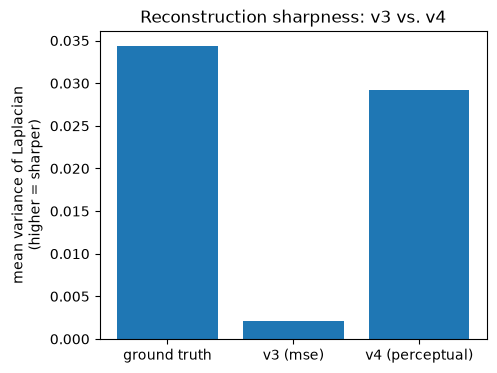

In [20]:
LAPLACIAN_KERNEL = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
LUMA_WEIGHTS = np.array([0.299, 0.587, 0.114], dtype=np.float32)  # standard RGB -> luma


def sharpness_scores(images):
    """Variance of the Laplacian response per image; higher = sharper."""
    return np.array([
        convolve(img @ LUMA_WEIGHTS, LAPLACIAN_KERNEL, mode="reflect").var()
        for img in images
    ])


autoencoder_v3 = models.load_model("./models/autoencoder_v3.keras")
predictions_v3 = autoencoder_v3.predict(example_images)

sharpness_real = sharpness_scores(example_images)
sharpness_v3 = sharpness_scores(predictions_v3)
sharpness_v4 = sharpness_scores(predictions)

print(f"mean sharpness, ground truth:           {sharpness_real.mean():.5f}")
print(f"mean sharpness, v3 (plain mse) recon:    {sharpness_v3.mean():.5f}")
print(f"mean sharpness, v4 (perceptual) recon:   {sharpness_v4.mean():.5f}")

plt.figure(figsize=(5, 4))
plt.bar(
    ["ground truth", "v3 (mse)", "v4 (perceptual)"],
    [sharpness_real.mean(), sharpness_v3.mean(), sharpness_v4.mean()],
)
plt.ylabel("mean variance of Laplacian\n(higher = sharper)")
plt.title("Reconstruction sharpness: v3 vs. v4")
plt.show()

## 5. Embed using the encoder <a name="encode"></a>

In [21]:
# Encode the example images
embeddings = encoder.predict(example_images)

  1/157 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step

 27/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  

 51/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 73/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 96/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

113/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

133/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

150/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [22]:
# Some examples of the embeddings
print(embeddings[:10])

[[-2.06265712e+00  1.57130301e+00  2.38841510e+00 -1.66703570e+00
   9.45096686e-02 -1.57525301e-01  1.04728317e+01 -9.97126043e-01
   3.59926510e+00  8.84049225e+00 -6.64897144e-01 -1.76091766e+00
   3.66423106e+00 -3.75287151e+00 -7.61146784e-01 -5.32907820e+00
   3.15415955e+00 -1.36646283e+00 -1.79602718e+00  3.58971548e+00
   4.80625963e+00  2.92266607e+00 -8.34068966e+00  4.61386144e-01
  -6.03387737e+00 -1.84709620e+00 -3.76829767e+00 -4.27950668e+00
   1.83336985e+00  3.09107137e+00 -3.11990142e+00  2.57228947e+00]
 [ 3.43997329e-01 -3.27401447e+00 -2.99957943e+00 -3.02586168e-01
   5.19636035e-01  1.04120455e+01 -4.72680426e+00  2.12857008e+00
  -2.44747806e+00  7.53218794e+00  9.37107754e+00  7.37175494e-02
  -1.03669298e+00  2.34498501e+00 -7.36126184e+00 -3.95469618e+00
  -5.97873807e-01  2.18525386e+00  4.30703402e+00  1.43667927e+01
   5.25440550e+00 -1.26973772e+01  9.40011883e+00 -2.48247290e+00
   1.63146150e+00 -1.20538747e+00 -7.00197506e+00 -5.42092943e+00
  -7.6082

### 5a. Visualizing a higher-dimensional latent space

With `EMBEDDING_DIM = 32` the raw embedding can no longer be scatter-plotted directly — plotting two arbitrary axes out of 32 would be just as uninformative as before. Instead we project the full 32-dim embedding down to 2D **only for visualization**, using two standard techniques:

- **PCA**: a fast, linear projection onto the 2 directions of highest variance. Good as a sanity check, but can hide non-linear cluster structure.
- **t-SNE**: a non-linear projection that explicitly tries to preserve local neighborhoods, so it's much better at revealing cluster structure that genuinely exists in the embedding — at the cost of being slower and not preserving global distances.

If classes still overlap heavily even in the t-SNE projection, that's a strong signal the embedding itself doesn't separate classes well (not just a 2D-plotting artifact).

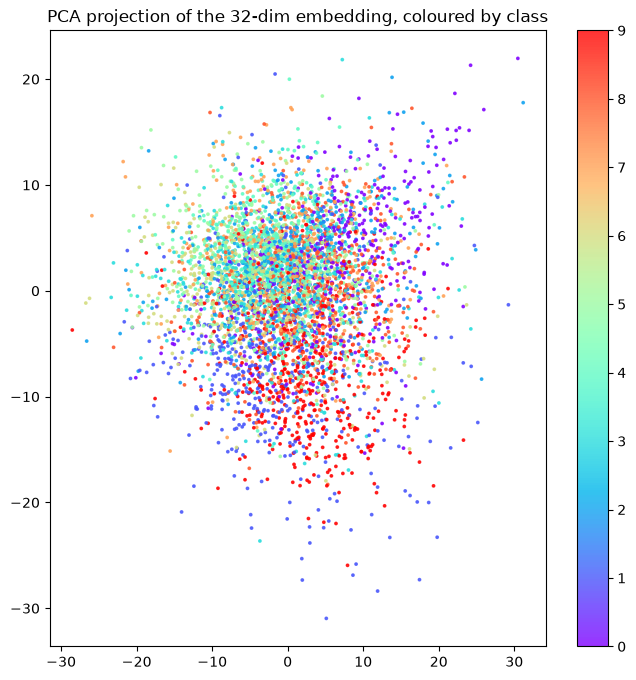

In [23]:
# PCA projection of the embedding, coloured by class
pca = PCA(n_components=2)
embeddings_pca = pca.fit_transform(embeddings)

figsize = 8
plt.figure(figsize=(figsize, figsize))
scatter = plt.scatter(
    embeddings_pca[:, 0],
    embeddings_pca[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar(scatter)
plt.title("PCA projection of the 32-dim embedding, coloured by class")
plt.show()

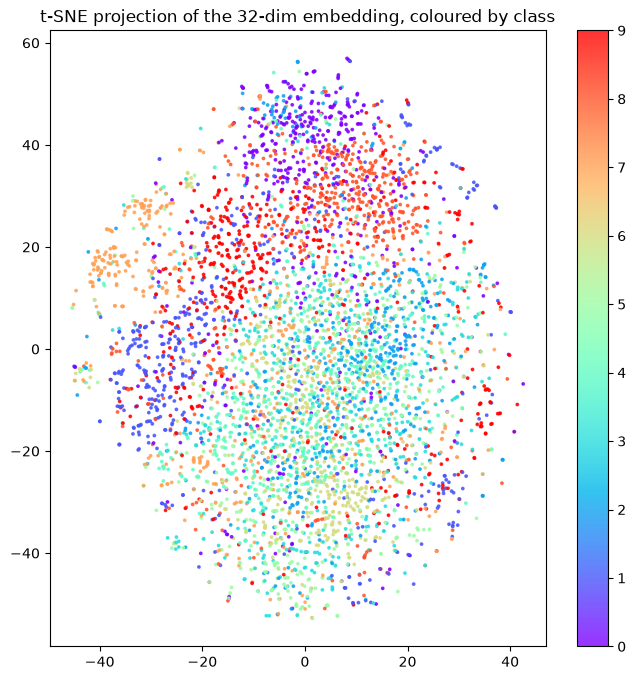

In [24]:
# t-SNE projection of the embedding, coloured by class
tsne = TSNE(n_components=2, init="pca", perplexity=30, random_state=42)
embeddings_tsne = tsne.fit_transform(embeddings)

figsize = 8
plt.figure(figsize=(figsize, figsize))
scatter = plt.scatter(
    embeddings_tsne[:, 0],
    embeddings_tsne[:, 1],
    cmap="rainbow",
    c=example_labels,
    alpha=0.8,
    s=3,
)
plt.colorbar(scatter)
plt.title("t-SNE projection of the 32-dim embedding, coloured by class")
plt.show()

### 5b. Quantifying class separability: a k-NN probe

Rather than judging separability by eye, a more rigorous diagnostic is to treat the embedding as features for a simple classifier and measure accuracy on held-out data. If the embedding genuinely carries class information, even a simple k-NN classifier should beat random guessing (10% for 10 balanced classes) by a wide margin. If it barely beats random guessing, the embedding — however it looks on a 2D plot — just isn't class-discriminative, and no amount of plotting will fix that; the training objective itself needs to change (e.g. add a supervised or contrastive loss) if class separability is actually the goal.

We compare two feature sets on the same train/test split of the 5000 example images: raw flattened pixels (3072-dim, zero learned compression) vs. the autoencoder's 32-dim embedding.

In [25]:
labels_flat = example_labels.ravel()
pixels_flat = example_images.reshape(len(example_images), -1)

(
    emb_train, emb_test,
    pix_train, pix_test,
    y_train_knn, y_test_knn,
) = train_test_split(
    embeddings,
    pixels_flat,
    labels_flat,
    test_size=0.2,
    random_state=42,
    stratify=labels_flat,
)

knn_embedding = KNeighborsClassifier(n_neighbors=5).fit(emb_train, y_train_knn)
acc_embedding = accuracy_score(y_test_knn, knn_embedding.predict(emb_test))

knn_pixels = KNeighborsClassifier(n_neighbors=5).fit(pix_train, y_train_knn)
acc_pixels = accuracy_score(y_test_knn, knn_pixels.predict(pix_test))

print(f"k-NN accuracy on raw pixels:          {acc_pixels:.3f}")
print(f"k-NN accuracy on 32-dim AE embedding: {acc_embedding:.3f}")
print(f"random-guess baseline (10 classes):   0.100")

k-NN accuracy on raw pixels:          0.269
k-NN accuracy on 32-dim AE embedding: 0.419
random-guess baseline (10 classes):   0.100


### Takeaways: what actually moves class separability — and what doesn't

The changes in this notebook (bigger bottleneck, more capacity, a better-matched loss, a properly monitored training schedule, and honest 2D projections instead of a forced 2D bottleneck) should make the embedding genuinely better — for reconstruction, and the k-NN probe above should read measurably higher than whatever a 2-dim bottleneck could achieve. But none of this changes the fundamental fact that **a plain autoencoder is never told what a class is**. If the goal is specifically good class separation, the next steps — in roughly increasing effort / payoff — are:

1. **Supervised or semi-supervised autoencoder**: add a small classification head on top of the embedding and train it jointly with an auxiliary cross-entropy loss against `y_train`/`y_test`. Now the embedding is directly optimized to be class-separable, not just reconstruction-sufficient.
2. **Contrastive / self-supervised learning** (e.g. SimCLR-style): pulls augmented views of the *same* image together and pushes different images apart, without needing reconstruction at all. This is the modern standard for embeddings that cluster by semantic content.
3. **Just train a supervised CNN classifier directly** on CIFAR-10 if classification accuracy is the actual end goal — skip the autoencoder bottleneck entirely. It will outperform any autoencoder-derived feature, because it's the only one of these options actually optimized for that objective.

See also `autoencoder_on_CIFAR-10_v2_vae.ipynb` in this folder for the VAE variant — note that a VAE's KL term makes the latent space smoother and more continuous (better for *generating* new images), which is a different property from class separability and should not be expected to fix the blob either.